# 03. Popularity bias

**Question.** Are popular teams overpriced? That is, at the same tipoff price, does the more popular team win less often than its price implies?

**Plan.** This notebook follows `ANALYSIS_PLAN.md` section 9.1, which was committed before any result here was computed. All tests are two-sided at the 0.05 level.

**Data.** `data/processed/snapshots.csv`, main sample at horizon 0, and `data/processed/team_metro_population.csv`.

**Seed.** The bootstrap uses seed 4981 and 2,000 replicates, as in the plan.

In [1]:
import sys
sys.path.insert(0, "../src")

import pandas as pd
from IPython.display import display

from csv_io import write_csv
from metro_population import load_metro_population
from popularity import (MEASURES, RESULTS_DIR, analyze_measure, load_sample,
                        measure_correlation, scatter_figure, team_measures)
from stats_tools import B, SEED

RESULTS_DIR.mkdir(exist_ok=True)
print(f"Bootstrap: B = {B:,}, seed = {SEED}")

Bootstrap: B = 2,000, seed = 4981


## 1. The two popularity measures

**Volume.** For each game and each team, the average number of contracts traded on the team's own market per game, over all its other games in the season. The current game is left out, so a game's own trading never enters its own measure.

**Metro population.** The July 1, 2025 population estimate of the metropolitan area that contains the team's arena. `python src/metro_population.py` builds the table from the two official files below.

In [2]:
metro = load_metro_population()
display(metro[["team", "metro_area", "area_type", "population", "reference_date", "retrieved"]])
for source, url in metro[["source", "source_url"]].drop_duplicates().itertuples(index=False):
    print(f"{source}\n  {url}")

,team,metro_area,area_type,population,reference_date,retrieved
0,ATL,"Atlanta-Sandy Springs-Roswell, GA",MSA,6482182,2025-07-01,2026-11-23
1,BKN,"New York-Newark-Jersey City, NY-NJ",MSA,20112448,2025-07-01,2026-11-23
2,BOS,"Boston-Cambridge-Newton, MA-NH",MSA,5034221,2025-07-01,2026-11-23
3,CHA,"Charlotte-Concord-Gastonia, NC-SC",MSA,2938830,2025-07-01,2026-11-23
4,CHI,"Chicago-Naperville-Elgin, IL-IN",MSA,9434123,2025-07-01,2026-11-23
5,CLE,"Cleveland, OH",MSA,2165775,2025-07-01,2026-11-23
6,DAL,"Dallas-Fort Worth-Arlington, TX",MSA,8477157,2025-07-01,2026-11-23
7,DEN,"Denver-Aurora-Centennial, CO",MSA,3092037,2025-07-01,2026-11-23
8,DET,"Detroit-Warren-Dearborn, MI",MSA,4390913,2025-07-01,2026-11-23
9,GSW,"San Francisco-Oakland-Fremont, CA",MSA,4630041,2025-07-01,2026-11-23


US Census Bureau, Metropolitan Statistical Area population totals, Vintage 2025
  https://www.census.gov/data/tables/time-series/demo/popest/2020s-total-metro-and-micro-statistical-areas.html
Statistics Canada, Table 17-10-0148-01, population estimates, July 1, by census metropolitan area
  https://www150.statcan.gc.ca/t1/tbl1/en/tv.action?pid=1710014801


The table has one row per team. Los Angeles (LAL, LAC) and New York (NYK, BKN) each appear twice with the same value. The largest area is New York, with 20.1 million people, and the smallest is New Orleans, with 0.97 million. Both sources give estimates for July 1, 2025, and both were retrieved on 2026-11-23.

## 2. How the two measures relate across teams

This section is descriptive. It uses each team's season-average volume (the measure of plan section 4) and its metro population. No test is attached.

In [3]:
teams = team_measures(metro)
corr = measure_correlation(teams)
write_csv(teams, RESULTS_DIR / "popularity_team_measures.csv")
write_csv(corr, RESULTS_DIR / "popularity_correlation.csv")
display(corr.round(3))
display(teams.round(0))

,n_teams,pearson_log_log,spearman_rank
0,30,0.222,0.125


,team,games,mean_pregame_contracts,metro_area,metro_population,volume_rank,metro_rank
0,LAL,82,1099305.0,"Los Angeles-Long Beach-Anaheim, CA",12844441,1,3
1,SAS,82,830013.0,"San Antonio-New Braunfels, TX",2813140,2,21
2,DEN,82,694381.0,"Denver-Aurora-Centennial, CO",3092037,3,18
3,DET,82,668628.0,"Detroit-Warren-Dearborn, MI",4390913,4,16
4,NYK,82,651208.0,"New York-Newark-Jersey City, NY-NJ",20112448,5,1
5,OKC,82,636798.0,"Oklahoma City, OK",1512813,6,27
6,BOS,82,608052.0,"Boston-Cambridge-Newton, MA-NH",5034221,7,14
7,PHI,82,589829.0,"Philadelphia-Camden-Wilmington, PA-NJ-DE-MD",6329118,8,12
8,GSW,81,528740.0,"San Francisco-Oakland-Fremont, CA",4630041,9,15
9,HOU,82,491148.0,"Houston-Pasadena-The Woodlands, TX",7904627,10,7


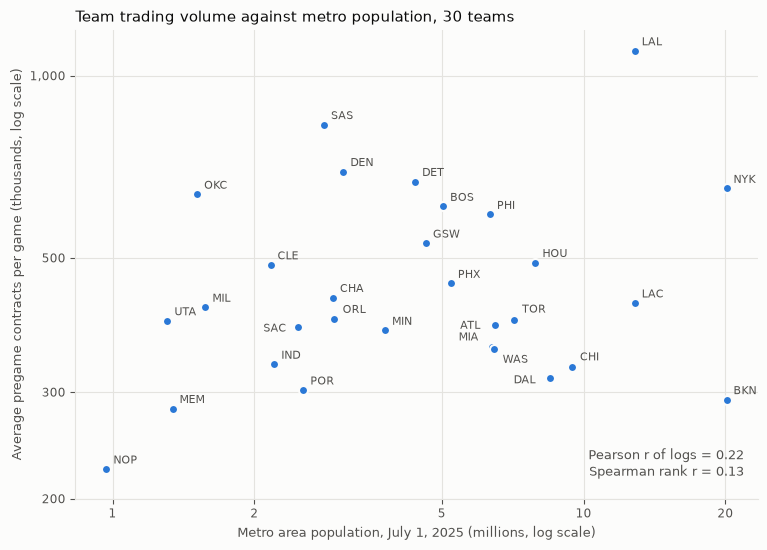

In [4]:
fig = scatter_figure(teams, corr, RESULTS_DIR / "popularity_scatter.png")

Across the 30 teams the two measures are only weakly related. The Pearson correlation of the logs is 0.22 and the Spearman rank correlation is 0.13.

Some examples from the table: San Antonio is 2nd in volume and 21st in metro population. Oklahoma City is 6th and 27th. Chicago is 25th and 5th. Brooklyn is 28th in volume and shares the largest metro area. The Lakers are high on both (1st, and tied 3rd), and New Orleans is last on both.

So the two measures rank teams differently. They are two separate ways to define popularity, not two readings of the same thing.

## 3. Sample and popularity gaps

For each game, the gap is log(home team's measure) minus log(away team's measure). A positive gap means the home team is the more popular one.

In [5]:
d = load_sample(metro)
print(f"{len(d):,} games, {d['game_date'].nunique()} game dates, "
      f"{d['home_team'].nunique()} home teams")
display(d[["gap_volume", "gap_metro"]].describe().round(3))

1,229 games, 164 game dates, 30 home teams


,gap_volume,gap_metro
count,1229.000,1229.000
mean,0.002,-0.004
std,0.500,1.128
min,-1.592,-3.031
25%,-0.328,-0.825
50%,0.002,-0.003
75%,0.329,0.805
max,1.618,3.031


The sample is the same 1,229 games as in notebook 02. Both gaps are centered near zero, because every team plays at home and away.

The volume gap has a standard deviation of 0.50 and runs from -1.59 to 1.62. The metro gap is more spread out: its standard deviation is 1.13 and it runs from -3.03 to 3.03. For scale, a gap of 0.69 means the home team's measure is twice the away team's.

## 4. The test

The model, fitted once per measure:

logit P(home win) = a + b · logit(p) + c · gap

Standard errors are clustered by home team. The test of interest is c = 0. A negative c means the more popular team wins less often than its price implies, so it is overpriced. `boot_lo` and `boot_hi` are the 95% percentile interval from the block bootstrap by game date.

In [6]:
out = {measure: analyze_measure(d, measure) for measure in MEASURES}
logistic = pd.concat([out[m]["logistic"] for m in MEASURES], ignore_index=True)
bootstrap = pd.concat([out[m]["bootstrap"] for m in MEASURES], ignore_index=True)
write_csv(logistic, RESULTS_DIR / "popularity_logistic.csv")
write_csv(bootstrap, RESULTS_DIR / "popularity_bootstrap.csv")
display(logistic.round(4))

,measure,term,estimate,se_cluster,ci_lo,ci_hi,null_value,z,p_value,n,n_clusters,boot_lo,boot_hi
0,volume,intercept_a,0.0613,0.0404,-0.0179,0.1406,0.0,1.5170,0.1293,1229,30,-0.0509,0.1844
1,volume,slope_b,0.8799,0.0616,0.7591,1.0006,1.0,-1.9505,0.0511,1229,30,0.7394,1.0385
2,volume,gap_c,0.6110,0.1352,0.3460,0.8760,0.0,4.5192,0.0000,1229,30,0.3259,0.8931
3,metro,intercept_a,0.0201,0.0435,-0.0651,0.1053,0.0,0.4627,0.6436,1229,30,-0.0893,0.1404
4,metro,slope_b,1.0313,0.0611,0.9115,1.1511,1.0,0.5122,0.6085,1229,30,0.9052,1.1801
5,metro,gap_c,0.0389,0.0513,-0.0616,0.1395,0.0,0.7586,0.4481,1229,30,-0.0736,0.1550


**Volume gap.** c = 0.611, with clustered SE 0.135 (z = 4.52, p < 0.0001). The clustered 95% interval is 0.346 to 0.876 and the bootstrap interval is 0.326 to 0.893. Both exclude 0, so by the plan's rule the result is robust.

The sign is positive. At the same price, the team with more trading volume won more often than its price implied. Under the plan's reading, that is the opposite of popular teams being overpriced: in this sample the high-volume teams were underpriced.

In the same model the slope is b = 0.880 (SE 0.062). The test of b = 1 gives p = 0.051, just above the 0.05 level, and the bootstrap interval, 0.739 to 1.039, contains 1. The intercept, a = 0.061, is not distinguishable from 0 (p = 0.13).

**Metro gap.** c = 0.039, with clustered SE 0.051 (p = 0.45). The clustered interval, -0.062 to 0.139, and the bootstrap interval, -0.074 to 0.155, both contain 0. There is no evidence that teams from larger metro areas are overpriced or underpriced. a and b are close to their values in notebook 02 (0.020 and 1.031 here).

The two measures give different answers. Section 2 showed that they rank teams differently.

**A caution on the volume result.** The leave-one-out average uses a team's games from the whole season, including games played after the one being priced. If trading in a team's games grew during the season because the team kept winning, this measure would carry information that was not available at tipoff. This notebook cannot separate that from mispricing. Notebook 05 uses a volume measure built from earlier games only.

## 5. The size of c in plain terms

`gap_sd` is the standard deviation of the gap across games. `c_per_sd` is c times that. `avg_effect_per_sd` is the average change in the home team's fitted win probability when the gap is one standard deviation larger and the price stays the same. The bootstrap keeps the step at the full-sample standard deviation in every replicate.

In [7]:
effects = pd.concat([out[m]["effects"] for m in MEASURES], ignore_index=True)
write_csv(effects, RESULTS_DIR / "popularity_effects.csv")
display(effects.round(4))

,measure,gap_sd,gap_c,c_per_sd,c_per_sd_boot_lo,c_per_sd_boot_hi,avg_effect_per_sd,avg_effect_boot_lo,avg_effect_boot_hi
0,volume,0.4997,0.6110,0.3053,0.1628,0.4462,0.0574,0.0307,0.0819
1,metro,1.1285,0.0389,0.0439,-0.0831,0.1750,0.0085,-0.0159,0.0330


**Volume.** One standard deviation of the volume gap is 0.50. That is a ratio of about 1.65 between the two teams' average volumes. A gap one SD larger adds 0.305 to the log odds of a home win (bootstrap interval 0.163 to 0.446). On average that is 5.7 percentage points of win probability at the same price (interval 3.1 to 8.2 points).

**Metro.** One standard deviation of the metro gap is 1.13, a population ratio of about 3.1. A gap one SD larger adds 0.044 to the log odds (interval -0.083 to 0.175). On average that is 0.9 percentage points (interval -1.6 to 3.3 points).

## 6. Full bootstrap summary

In [8]:
display(bootstrap.round(4))

,measure,statistic,estimate,boot_mean,boot_se,boot_lo,boot_hi,B,n_dates,seed
0,volume,intercept_a,0.0613,0.0645,0.0601,-0.0509,0.1844,2000,164,4981
1,volume,slope_b,0.8799,0.8854,0.0768,0.7394,1.0385,2000,164,4981
2,volume,gap_c,0.6110,0.6128,0.1457,0.3259,0.8931,2000,164,4981
3,volume,c_per_sd,0.3053,0.3062,0.0728,0.1628,0.4462,2000,164,4981
4,volume,avg_effect_per_sd,0.0574,0.0572,0.0130,0.0307,0.0819,2000,164,4981
5,metro,intercept_a,0.0201,0.0231,0.0597,-0.0893,0.1404,2000,164,4981
6,metro,slope_b,1.0313,1.0374,0.0708,0.9052,1.1801,2000,164,4981
7,metro,gap_c,0.0389,0.0388,0.0576,-0.0736,0.1550,2000,164,4981
8,metro,c_per_sd,0.0439,0.0438,0.0650,-0.0831,0.1750,2000,164,4981
9,metro,avg_effect_per_sd,0.0085,0.0084,0.0124,-0.0159,0.0330,2000,164,4981


The bootstrap means are close to the point estimates. The bootstrap standard errors of c (0.146 for volume, 0.058 for metro) are a little larger than the clustered ones (0.135 and 0.051). Allowing for dependence between games on the same date does not change either conclusion.

**What the numbers show.** With the volume measure, c is positive and clearly different from 0: teams with more trading volume won more often than their prices implied. That is the opposite of the overpricing hypothesis, and it comes with the caution in section 4. With the metro measure, c is close to 0 and not significant. Neither measure shows popular teams being overpriced.